In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load dataset 
df = pd.read_csv("/Users/arjolaarapi-gjini/Desktop/amz_uk_price_prediction_dataset.csv")

# Quick overview
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


In [8]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [10]:
# Exploring Numerical and Qualitative Variables
num = df.select_dtypes (include="number")
cat = df.select_dtypes(exclude= "number")

In [11]:
num

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [12]:
cat

,asin,title,isBestSeller,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",True,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",False,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,False,Hi-Fi Speakers
...,...,...,...,...
2443646,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",False,Motorbike Clothing
2443647,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,False,Motorbike Clothing
2443648,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,False,Motorbike Clothing
2443649,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,False,Motorbike Clothing


In [9]:
category_freq = df['category'].value_counts()
category_freq.head()
# Sports and Outdoors is the most frequent category

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [16]:
# Top 5 Most Frequent Categories
top5_categories = category_freq.head(5)
top5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

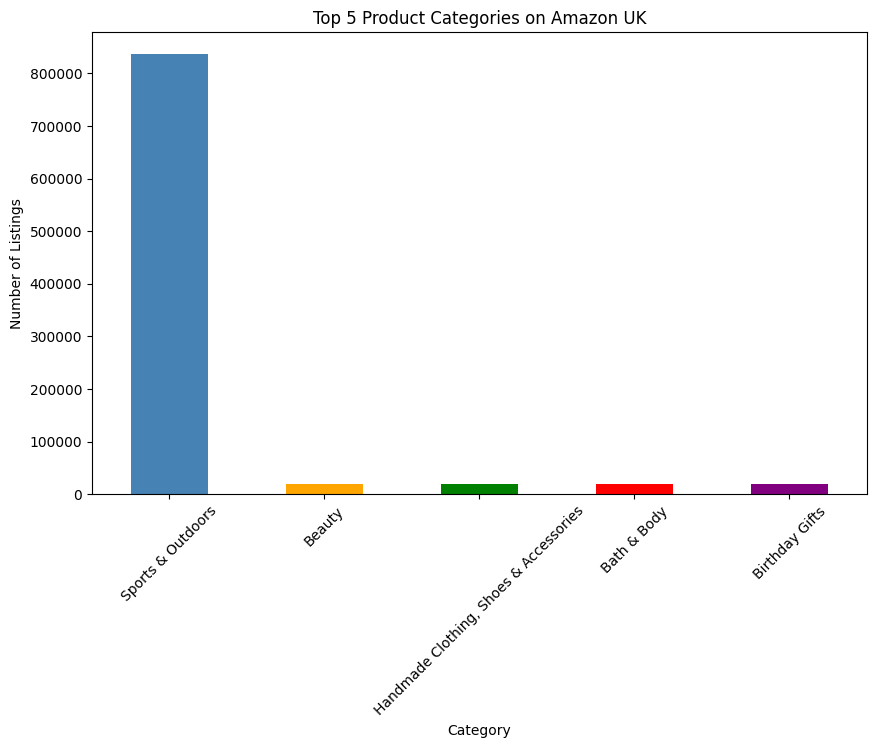

In [18]:
#Bar Chart
plt.figure(figsize=(10,6))

colors = ['steelblue', 'orange', 'green', 'red', 'purple']

top5_categories.plot(
    kind='bar',
    color=colors
)

plt.title("Top 5 Product Categories on Amazon UK")
plt.ylabel("Number of Listings")
plt.xlabel("Category")
plt.xticks(rotation=45)
plt.show()

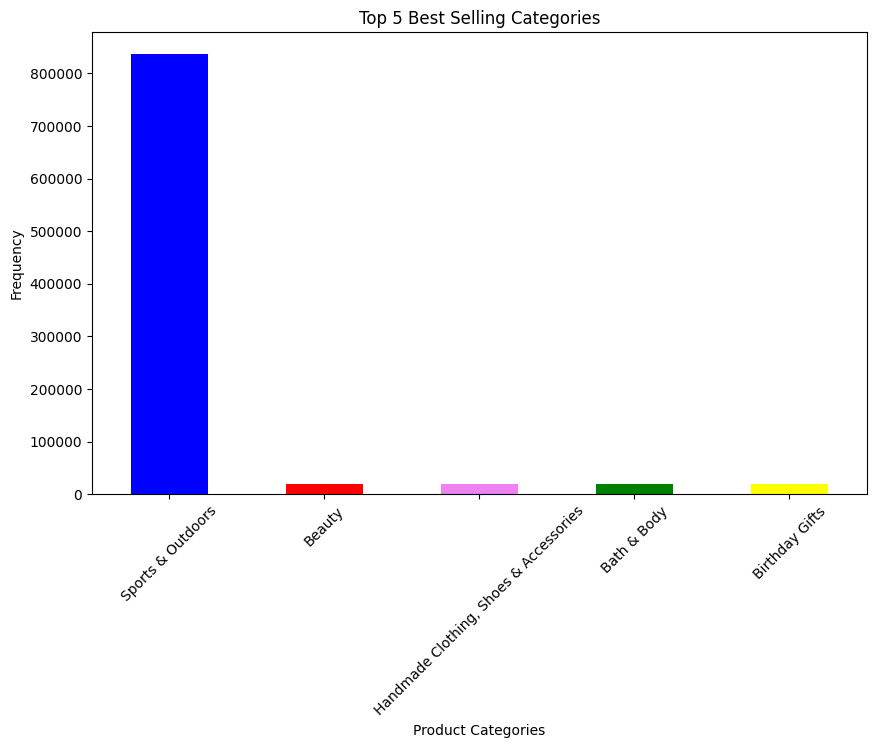

In [22]:
plt.figure(figsize=(10,6))
colors=['blue', 'red', 'violet', 'green', 'yellow']
top5_categories.plot(
    kind='bar',
    color=colors
)
plt.title("Top 5 Best Selling Categories")
plt.xlabel ("Product Categories")
plt.ylabel ("Frequency")
plt.xticks (rotation=45)

plt.show()

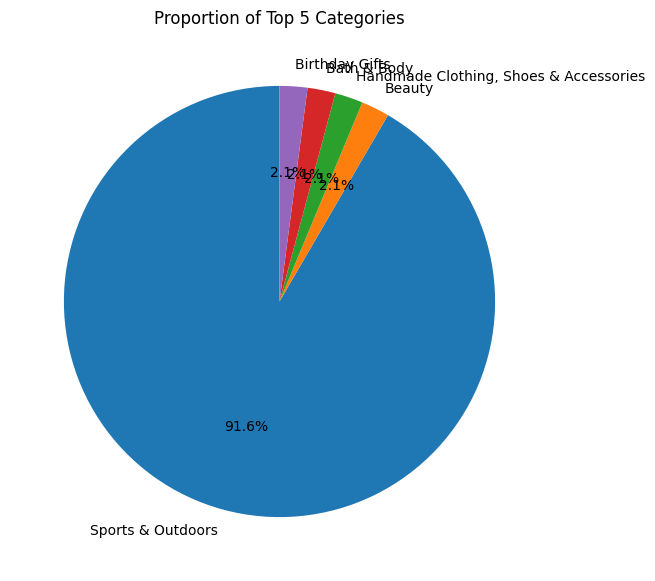

In [23]:
#Pie Chart
plt.figure(figsize=(7,7))
top5_categories.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.ylabel("")
plt.title("Proportion of Top 5 Categories")
plt.show()



In [29]:
# Measures of Central Tendency
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()
mean_price, median_price, mode_price


In [31]:
# Measures of Central Tendency and Dispersion
df['price'].describe()


count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [35]:
variance_price=df['price'].var()
std_price = df['price'].std()
iqr_price=df['price'].quantile(0.75)-df['price'].quantile(0.25)
variance_price, std_price, iqr_price

(np.float64(119445.48532254901),
 np.float64(345.60886175349873),
 np.float64(36.0))

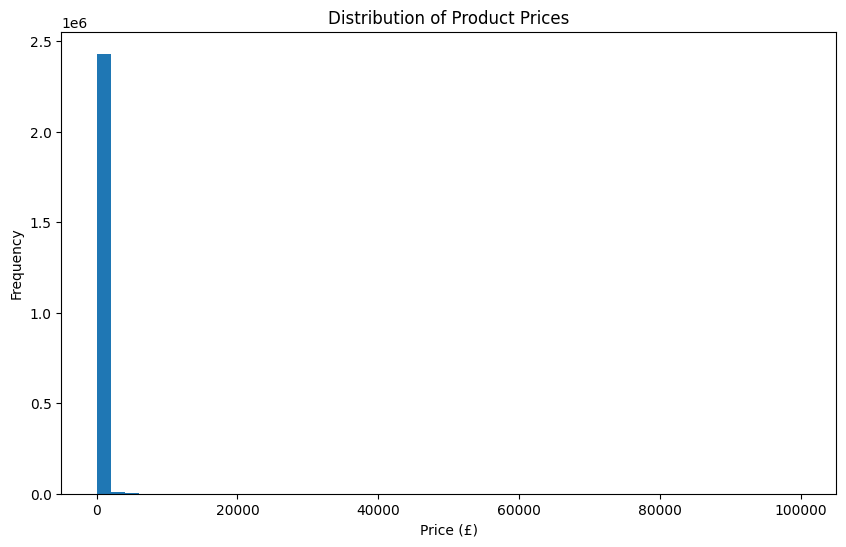

In [32]:
# Histogram
plt.figure(figsize=(10,6))
plt.hist(df['price'], bins=50)
plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")
plt.show()

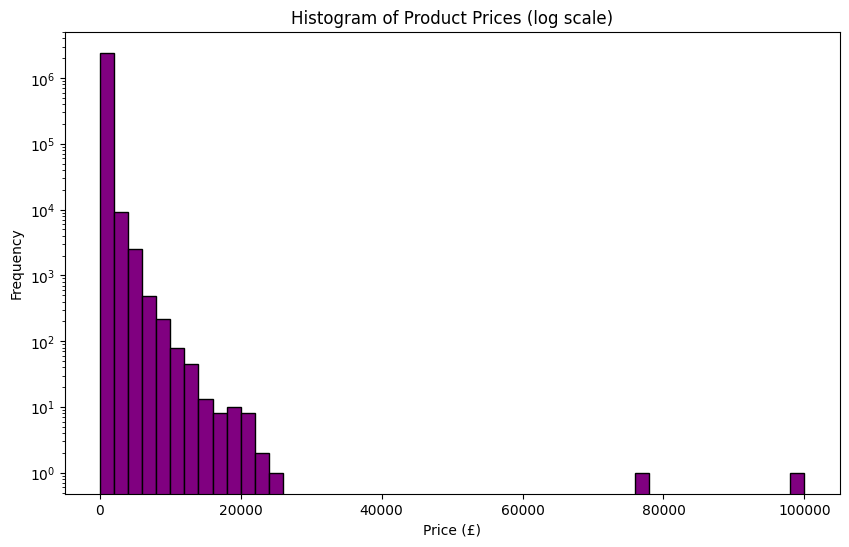

In [37]:
# Right-skewed Distribution- take the logs of prices
df['price'].plot.hist(bins=50, log=True, figsize=(10,6), color='purple', edgecolor='black')
plt.title("Histogram of Product Prices (log scale)")
plt.xlabel("Price (£)")
plt.show()

In [40]:
df['price'].isnull().sum()

np.int64(0)

In [41]:
(df['price'] <= 0).sum()

np.int64(20)

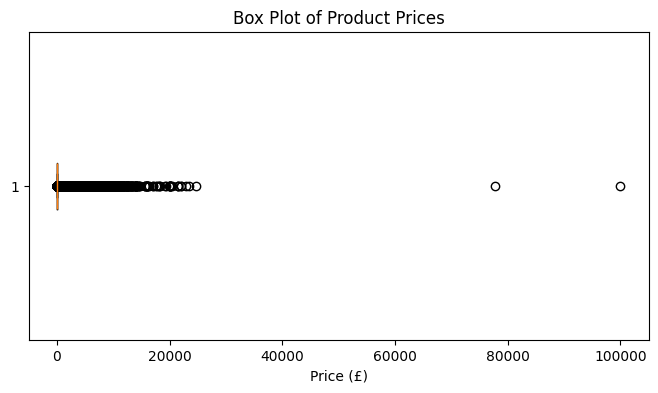

In [36]:
# Boxplot
plt.figure(figsize=(8,4))
plt.boxplot(df['price'], vert=False)
plt.title("Box Plot of Product Prices")
plt.xlabel("Price (£)")
plt.show()

In [43]:
cat

,asin,title,isBestSeller,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",True,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",False,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,False,Hi-Fi Speakers
...,...,...,...,...
2443646,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",False,Motorbike Clothing
2443647,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,False,Motorbike Clothing
2443648,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,False,Motorbike Clothing
2443649,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,False,Motorbike Clothing


In [44]:
df.head(5)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [52]:
df['stars'].value_counts()

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

In [45]:
# Measures of Central Tendency and Dispersion for Ratings
df['stars'].describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [48]:
stars_skew=df['stars'].skew()
stars_kurtosis = df['stars'].kurtosis()
stars_skew, stars_kurtosis
# Positive Skewness, Negative Kurtosis

(np.float64(0.08120735761080881), np.float64(-1.9260061280432994))

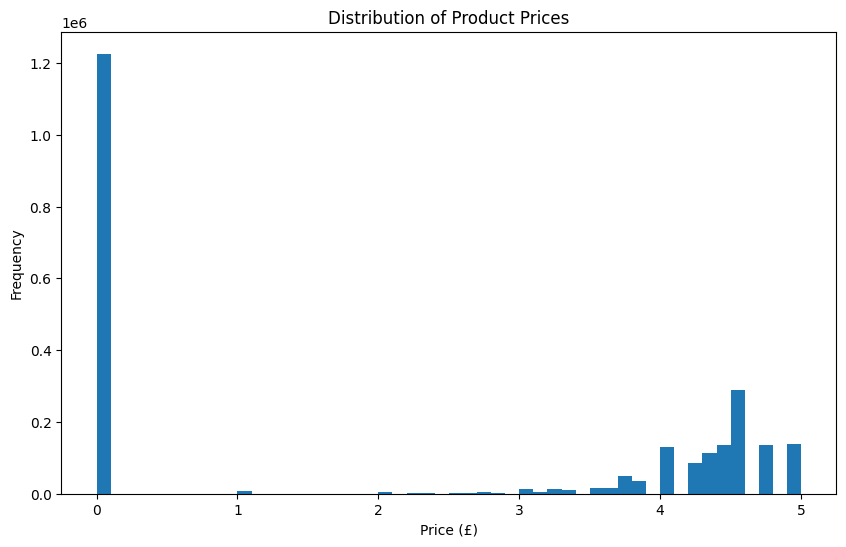

In [49]:
# Construct Histogram
plt.figure(figsize=(10,6))
plt.hist(df['stars'], bins=50)
plt.title("Distribution of Product Ratings")
plt.xlabel("Ratings")
plt.ylabel("Frequency")
plt.show()

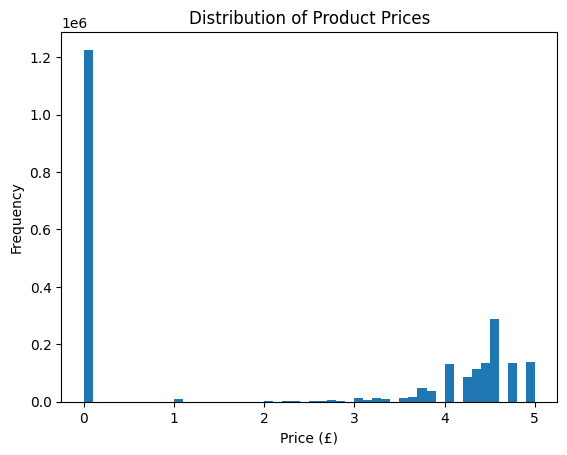

In [50]:
plt.hist(df['stars'], bins=50)
plt.title("Distribution of Product Ratings")
plt.xlabel("Ratings")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Final Comments: The histogram reveal a left-skewed distribution, with 50% of priduct having 0 star ratings, wide dispersion of the data